## 1. Load and Preprocess the Digits Dataset

In this section, we load the digits dataset from scikit-learn and focus only on the digits **0, 1, and 2**. We then standardize the data to have zero mean and unit variance, which is important for many machine learning algorithms. After preprocessing, we use **Principal Component Analysis (PCA)** to reduce the data to **2 dimensions** for easier visualization and clustering.


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load dataset
digits = load_digits()
X, y = digits.data, digits.target

# Select only classes 0, 1, 2
selected_classes = [0, 1, 2]
mask = np.isin(y, selected_classes)
X = X[mask]
y = y[mask]

# Standardize and apply PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Selected classes: {selected_classes}")
print(f"Reduced shape: {X_pca.shape}")

Selected classes: [0, 1, 2]
Reduced shape: (537, 2)


## 2. K-Means Clustering on PCA-Transformed Data

We apply the **K-Means clustering algorithm** to the 2D PCA-transformed data, specifying 3 clusters to match the number of selected digit classes (0, 1, and 2). The resulting cluster assignments are then compared visually to the true digit labels using scatter plots. This helps us assess how well the clustering aligns with the actual digit classes.


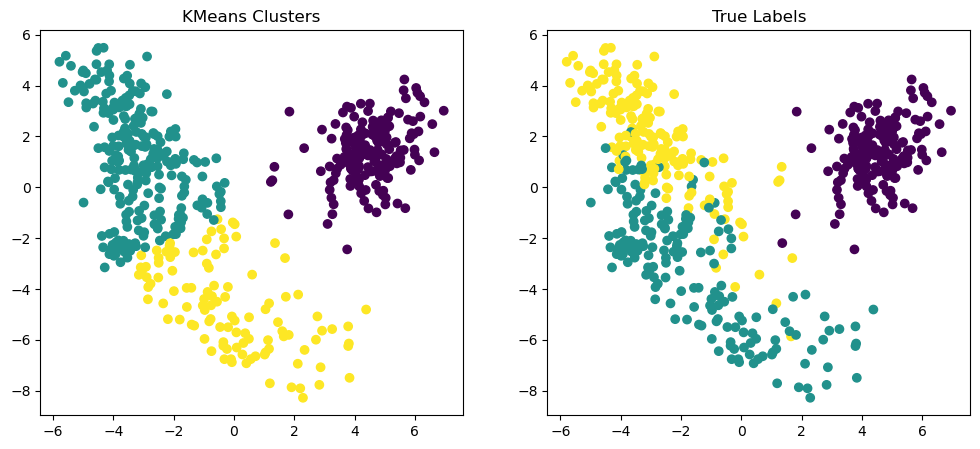

In [32]:
from sklearn.cluster import KMeans

# Fit KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_pca)

# Plot clusters vs true labels
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
plt.title("KMeans Clusters")

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.title("True Labels")

plt.show()

## 3. Elbow Method to Determine Optimal Number of Clusters

To determine the best number of clusters (**k**) for K-Means, we use the **elbow method**. This involves running K-Means for different values of k (from 1 to 10) and recording the **inertia** (sum of squared distances to the nearest cluster center). We then plot the inertia values to identify the "elbow point" — the value of k after which adding more clusters yields diminishing returns in reducing inertia.


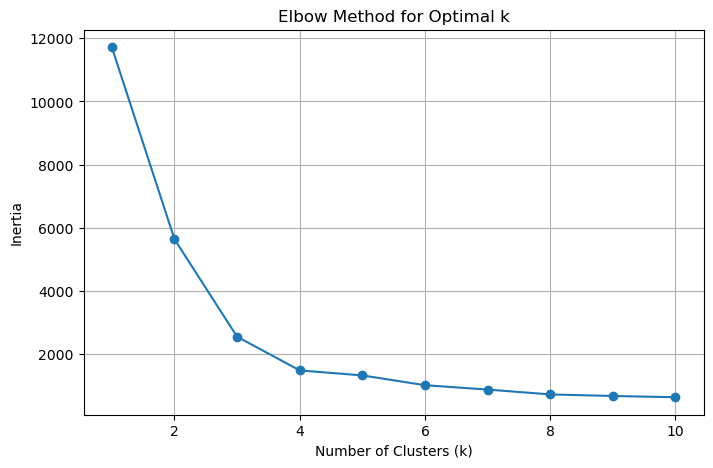

In [33]:
# Calculate inertia for k=1 to 10
inertias = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_pca)
    inertias.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.grid(True)
plt.show()

## 4. Gaussian Mixture Models (GMM) with Different Covariance Types

In this section, we apply **Gaussian Mixture Models (GMM)** to the PCA-reduced data using two different covariance types: `'full'` and `'diag'`. These models assume that data is generated from a mixture of Gaussian distributions. After fitting both models, we compare their **log-likelihoods**, which indicate how well each model fits the data. Higher log-likelihood values suggest a better fit.


Fitting GMM with full covariance...


Fitting GMM with diagonal covariance...


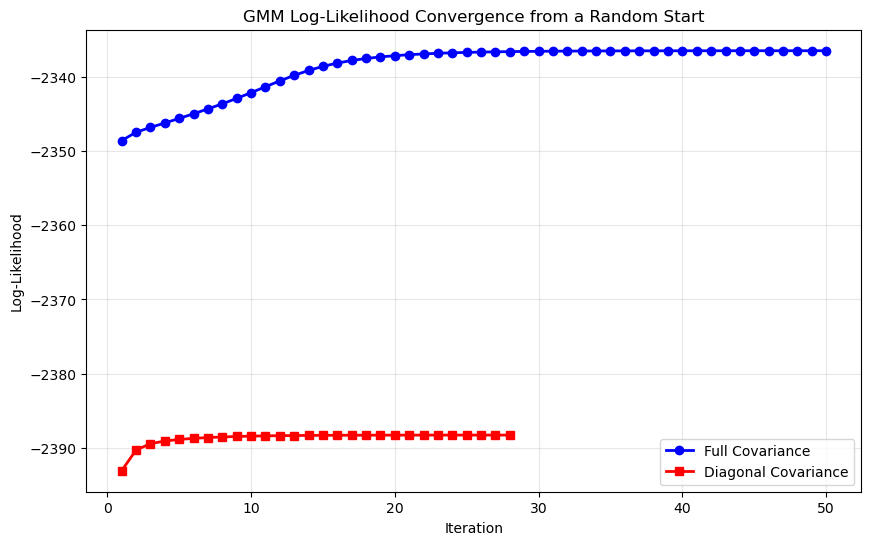


Full covariance converged in 50 iterations
Diagonal covariance converged in 28 iterations
Final log-likelihood (Full): -2336.46
Final log-likelihood (Diagonal): -2388.29


In [34]:
from sklearn.mixture import GaussianMixture
import numpy as np
import warnings
import matplotlib.pyplot as plt 

# Custom function to fit GMM with manual iteration tracking
# This allows us to monitor convergence step by step from a single random initialization
def fit_gmm_from_random_start(X, n_components, covariance_type, max_iter=100):
    """
    Fit a Gaussian Mixture Model with manual iteration tracking.
    
    Parameters:
    - X: Input data (n_samples, n_features)
    - n_components: Number of Gaussian components (clusters)
    - covariance_type: Type of covariance matrix ('full' or 'diag')
    - max_iter: Maximum number of iterations for convergence
    
    Returns:
    - gmm: Fitted GMM model
    - log_likelihoods: List of log-likelihood values at each iteration
    """
    log_likelihoods = []
    
    # Initialize GMM with specific parameters for controlled fitting
    gmm = GaussianMixture(
        n_components=n_components,       # Number of Gaussian components
        covariance_type=covariance_type, # Shape of covariance matrix
        n_init=1,                        # Only one random initialization attempt
        max_iter=1,                      # Start with 1 iteration, increment manually
        tol=1e-6,                        # Convergence tolerance
        random_state=42                  # Fixed seed for reproducibility
    )
    
    # Manual iteration loop to track convergence step by step
    for i in range(max_iter):
        # Suppress sklearn warnings for cleaner output
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=UserWarning)
            warnings.filterwarnings("ignore", category=RuntimeWarning) 
            
            # Fit the model for current iteration
            gmm.fit(X)
            
        # Calculate log-likelihood: score() returns per-sample likelihood, multiply by n_samples
        log_likelihood = gmm.score(X) * len(X)
        log_likelihoods.append(log_likelihood)
        
        # Check for convergence: if change in log-likelihood is below tolerance, stop
        if i > 0 and abs(log_likelihoods[-1] - log_likelihoods[-2]) < gmm.tol:
            break
            
        # Allow one more iteration for next step
        gmm.max_iter += 1
    
    return gmm, log_likelihoods

# Fit GMM with full covariance matrix
# Full covariance allows elliptical clusters with any orientation
print("Fitting GMM with full covariance...")
gmm_full, ll_full = fit_gmm_from_random_start(X_pca, 3, 'full')

# Fit GMM with diagonal covariance matrix  
# Diagonal covariance restricts clusters to axis-aligned ellipses
print("Fitting GMM with diagonal covariance...")
gmm_diag, ll_diag = fit_gmm_from_random_start(X_pca, 3, 'diag')

# Visualize convergence behavior of both models
plt.figure(figsize=(10, 6))

# Plot full covariance convergence (blue line with circles)
plt.plot(range(1, len(ll_full) + 1), ll_full, 'b-o', label='Full Covariance', linewidth=2)

# Plot diagonal covariance convergence (red line with squares)
plt.plot(range(1, len(ll_diag) + 1), ll_diag, 'r-s', label='Diagonal Covariance', linewidth=2)

# Configure plot appearance
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.title("GMM Log-Likelihood Convergence from a Random Start")
plt.legend()
plt.grid(True, alpha=0.3)  # Light grid for better readability
plt.show()

# Display convergence statistics and final performance metrics
print(f"\nFull covariance converged in {len(ll_full)} iterations")
print(f"Diagonal covariance converged in {len(ll_diag)} iterations")
print(f"Final log-likelihood (Full): {ll_full[-1]:.2f}")
print(f"Final log-likelihood (Diagonal): {ll_diag[-1]:.2f}")

# Analysis note: Higher log-likelihood indicates better fit to the data
# Full covariance typically achieves higher log-likelihood but takes more iterations
# Diagonal covariance converges faster but may have lower final log-likelihood

### GMM Convergence Analysis: Key Observations

During our analysis of the Gaussian Mixture Model (GMM) with the Expectation-Maximization (EM) algorithm, we observed a clear trade-off between model complexity and convergence speed. The **full covariance** model, with its greater flexibility in modeling cluster shapes, required 50 iterations to converge. In contrast, the simpler **diagonal covariance** model, which assumes axis-aligned clusters, converged in just 28 iterations. This highlights that while a less complex model can converge faster, the more flexible full model ultimately achieved a better fit, as indicated by its higher final log-likelihood of **-2336.46** compared to the diagonal model's **-2388.29**. The longer convergence time for the full model is a direct result of its more complex parameter space, which demands more iterations for the EM algorithm to find the optimal solution.
